<a href="https://colab.research.google.com/github/2025cschaithrarb-cmd/DAV-lab/blob/main/DAES_Loan_approval_predction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [46]:
# STEP 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [47]:
# STEP 2: Load the dataset

df = pd.read_csv('/content/loan_approval_dataset.csv')

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

Dataset loaded successfully!
Shape of dataset: (4269, 13)


In [48]:
# STEP 3: Basic Dataset Inspection

print("First 5 rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

First 5 rows:


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433

In [49]:
# STEP 4: Data Cleaning

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Check for missing values and duplicates
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nColumn names after cleaning:")
print(df.columns.tolist())

Missing values:
loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

Duplicate rows: 0

Column names after cleaning:
['loan_id', 'no_of_dependents', 'education', 'self_employed', 'income_annum', 'loan_amount', 'loan_term', 'cibil_score', 'residential_assets_value', 'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value', 'loan_status']


In [50]:
# STEP 5: Exploratory Data Analysis (EDA)

print("Statistical Summary:")
display(df.describe())

print("\nLoan Status Distribution:")
print(df['loan_status'].value_counts())

print("\nCategorical Values:")
print("Education:", df['education'].unique())
print("Self Employed:", df['self_employed'].unique())
print("Loan Status:", df['loan_status'].unique())

Statistical Summary:


,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07



Loan Status Distribution:
loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64

Categorical Values:
Education: [' Graduate' ' Not Graduate']
Self Employed: [' No' ' Yes']
Loan Status: [' Approved' ' Rejected']


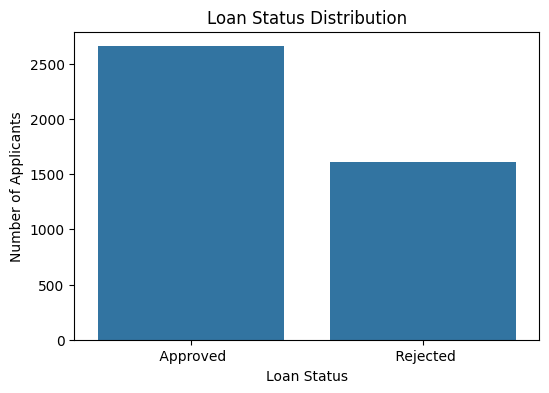

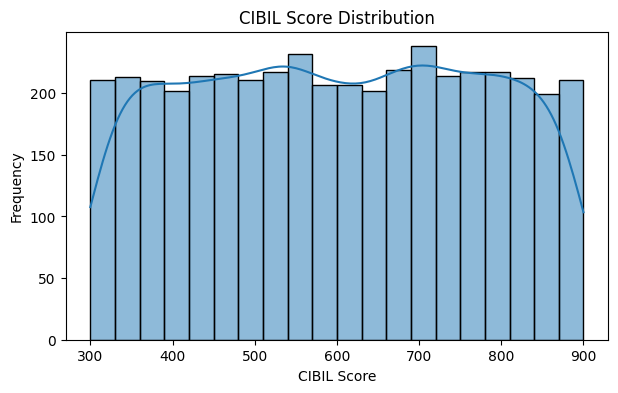

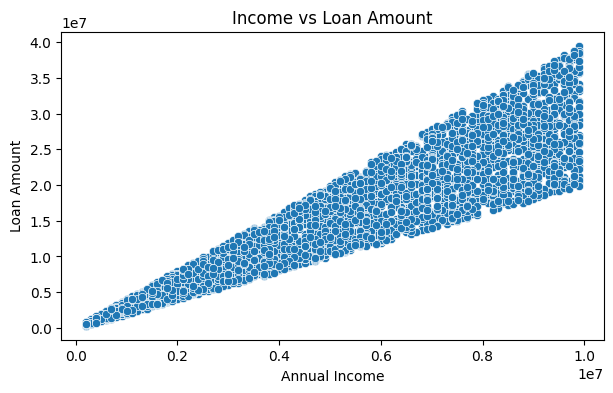

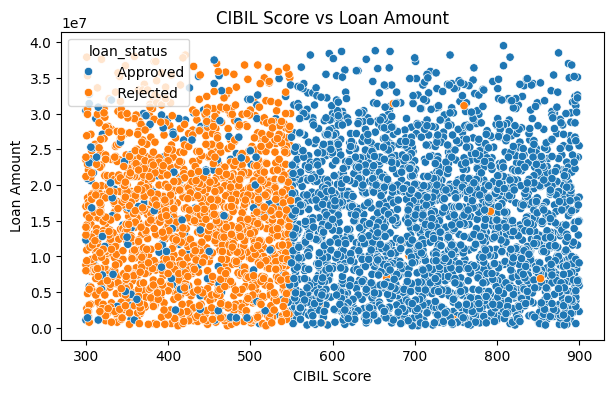

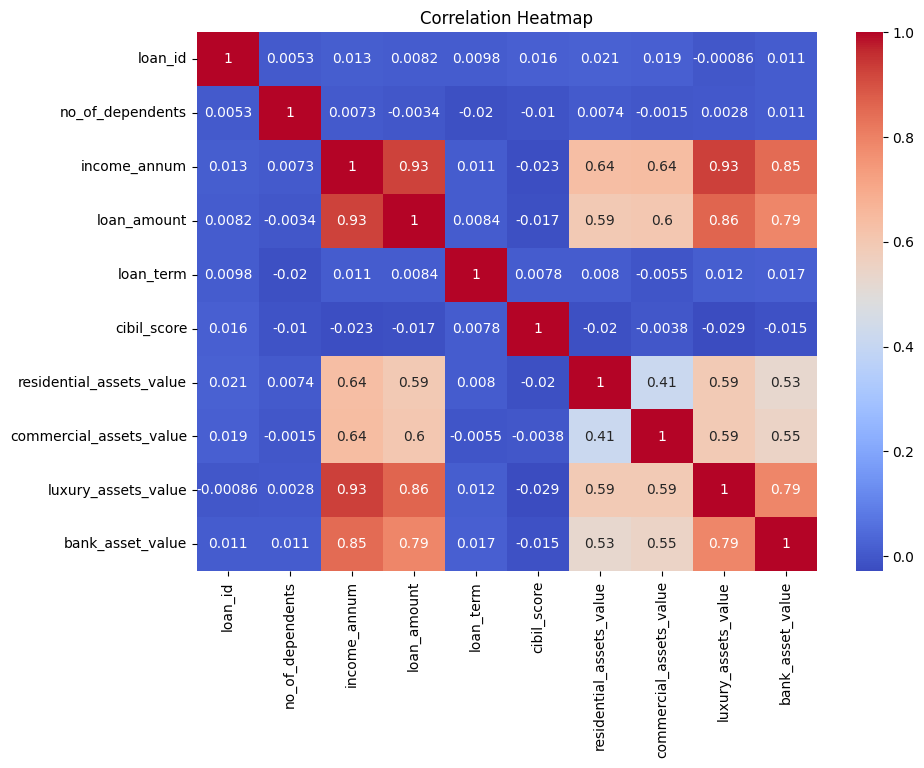

In [51]:
# STEP 6: Data Visualization

# 1. Loan Status Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='loan_status', data=df)
plt.title('Loan Status Distribution')
plt.xlabel('Loan Status')
plt.ylabel('Number of Applicants')
plt.show()

# 2. CIBIL Score Distribution
plt.figure(figsize=(7, 4))
sns.histplot(df['cibil_score'], bins=20, kde=True)
plt.title('CIBIL Score Distribution')
plt.xlabel('CIBIL Score')
plt.ylabel('Frequency')
plt.show()

# 3. Income vs Loan Amount
plt.figure(figsize=(7, 4))
sns.scatterplot(x='income_annum', y='loan_amount', data=df)
plt.title('Income vs Loan Amount')
plt.xlabel('Annual Income')
plt.ylabel('Loan Amount')
plt.show()

# 4. CIBIL Score vs Loan Amount by Loan Status
plt.figure(figsize=(7, 4))
sns.scatterplot(
    x='cibil_score',
    y='loan_amount',
    hue='loan_status',
    data=df
)
plt.title('CIBIL Score vs Loan Amount')
plt.xlabel('CIBIL Score')
plt.ylabel('Loan Amount')
plt.show()

# 5. Correlation Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df.select_dtypes(include=np.number).corr(),
            annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [52]:
# STEP 7: Categorical Encoding

# Strip leading/trailing whitespaces before mapping to avoid creating NaN values
df['education'] = df['education'].str.strip().map({
    'Graduate': 1,
    'Not Graduate': 0
})

df['self_employed'] = df['self_employed'].str.strip().map({
    'Yes': 1,
    'No': 0
})

df['loan_status'] = df['loan_status'].str.strip().map({
    'Approved': 1,
    'Rejected': 0
})

print("Categorical encoding completed successfully with whitespace stripping!")
display(df.head())

Categorical encoding completed successfully with whitespace stripping!


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1
1,2,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
2,3,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
3,4,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
4,5,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0


In [53]:
# STEP 8: Outlier Detection and Treatment

# Select numerical columns
numeric_columns = df.select_dtypes(include=np.number).columns

# Detect and treat outliers using IQR
for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # Replace outliers with the respective limits
    df[column] = df[column].clip(lower=lower_limit, upper=upper_limit)

print("Outlier detection and treatment completed successfully!")

Outlier detection and treatment completed successfully!


In [54]:
# STEP 9: Feature Engineering

# Create total asset value
df['total_asset_value'] = (
    df['residential_assets_value']
    + df['commercial_assets_value']
    + df['luxury_assets_value']
    + df['bank_asset_value']
)

# Create income-to-loan ratio
df['income_loan_ratio'] = df['income_annum'] / df['loan_amount']

print("Feature engineering completed successfully!")

display(df.head())

Feature engineering completed successfully!


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,total_asset_value,income_loan_ratio
0,1,2,1,0,9600000,29900000,12,778,2400000,17050000,22700000,8000000,1,50150000,0.321070
1,2,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0,17000000,0.336066
2,3,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0,57700000,0.306397
3,4,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0,52700000,0.267101
4,5,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0,55000000,0.404959


In [55]:
# STEP 10: Normalization and Standardization

from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Select numerical features
features = df.drop(columns=['loan_status', 'loan_id'])

# Normalization
normalizer = MinMaxScaler()
normalized_data = normalizer.fit_transform(features)

# Standardization
standardizer = StandardScaler()
standardized_data = standardizer.fit_transform(features)

print("Normalization completed successfully!")
print("Standardization completed successfully!")

print("\nNormalized data shape:", normalized_data.shape)
print("Standardized data shape:", standardized_data.shape)

Normalization completed successfully!
Standardization completed successfully!

Normalized data shape: (4269, 13)
Standardized data shape: (4269, 13)


PCA completed successfully!
Explained variance ratio: [0.42094737 0.08388949]


,Principal Component 1,Principal Component 2
0,3.003254,-0.501707
1,-1.492722,-0.785147
2,3.472222,-0.345971
3,2.743846,-0.682613
4,2.665314,1.113143


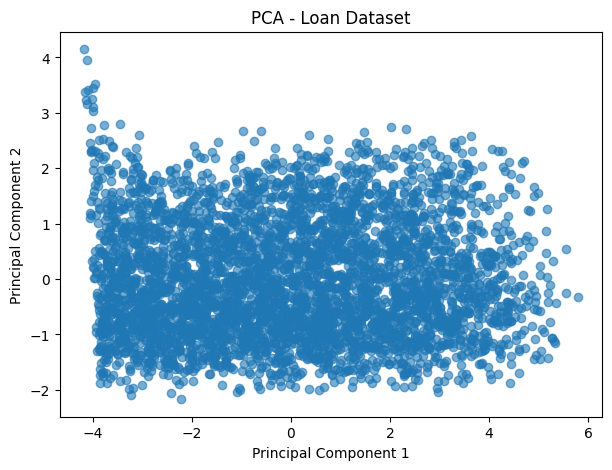

In [56]:
# STEP 11: Principal Component Analysis (PCA)

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select numerical features
features = df.drop(columns=['loan_status', 'loan_id'])

# Make sure all values are numeric
features = features.apply(pd.to_numeric, errors='coerce')

# Replace infinite values with NaN
features = features.replace([np.inf, -np.inf], np.nan)

# Remove columns containing only NaN values
features = features.dropna(axis=1, how='all')

# Fill remaining missing values with the column median
features = features.fillna(features.median())

# Standardize the data
scaler = StandardScaler()
standardized_data = scaler.fit_transform(features)

# Apply PCA
pca = PCA(n_components=2)
pca_data = pca.fit_transform(standardized_data)

# Create PCA DataFrame
pca_df = pd.DataFrame(
    pca_data,
    columns=['Principal Component 1', 'Principal Component 2']
)

print("PCA completed successfully!")
print("Explained variance ratio:", pca.explained_variance_ratio_)

display(pca_df.head())

# Visualize PCA
plt.figure(figsize=(7, 5))
plt.scatter(
    pca_df['Principal Component 1'],
    pca_df['Principal Component 2'],
    alpha=0.6
)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA - Loan Dataset')
plt.show()

In [57]:
# STEP 12: Train-Test Split

from sklearn.model_selection import train_test_split

# Define features and target
X = df.drop(columns=['loan_status', 'loan_id'])
y = df['loan_status']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Train-Test Split completed successfully!")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Train-Test Split completed successfully!
Training data: (3415, 13)
Testing data: (854, 13)


In [58]:
# REPAIR DATASET - FIX CATEGORICAL VALUES

# Reload original dataset
df = pd.read_csv('/content/loan_approval_dataset.csv')

# Clean column names
df.columns = df.columns.str.strip()

# Clean categorical values
for col in ['education', 'self_employed', 'loan_status']:
    df[col] = df[col].astype(str).str.strip().str.lower()

# Encode Education
df['education'] = df['education'].map({
    'graduate': 1,
    'not graduate': 0
})

# Encode Self Employed
df['self_employed'] = df['self_employed'].map({
    'yes': 1,
    'no': 0
})

# Encode Loan Status
df['loan_status'] = df['loan_status'].map({
    'approved': 1,
    'rejected': 0
})

# Check results
print("Dataset repaired successfully!")
print("\nMissing values:")
print(df.isnull().sum())

print("\nLoan Status:")
print(df['loan_status'].value_counts(dropna=False))

print("\nDataset shape:", df.shape)

Dataset repaired successfully!

Missing values:
loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64

Loan Status:
loan_status
1    2656
0    1613
Name: count, dtype: int64

Dataset shape: (4269, 13)


In [59]:
# STEP 13: LINEAR REGRESSION

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score

# Select features and target
X_lr = df.drop(columns=['loan_amount', 'loan_status', 'loan_id'])
y_lr = df['loan_amount']

# Convert features to numeric
X_lr = X_lr.apply(pd.to_numeric, errors='coerce')

# Replace infinite values
X_lr = X_lr.replace([np.inf, -np.inf], np.nan)

# Remove rows with missing target values
valid_rows = y_lr.notna() & np.isfinite(y_lr)
X_lr = X_lr.loc[valid_rows]
y_lr = y_lr.loc[valid_rows]

# Fill missing feature values
imputer = SimpleImputer(strategy='median')
X_lr = imputer.fit_transform(X_lr)

# Split dataset
X_lr_train, X_lr_test, y_lr_train, y_lr_test = train_test_split(
    X_lr, y_lr,
    test_size=0.2,
    random_state=42
)

# Train model
linear_model = LinearRegression()
linear_model.fit(X_lr_train, y_lr_train)

# Make predictions
y_lr_pred = linear_model.predict(X_lr_test)

# Evaluate model
mse = mean_squared_error(y_lr_test, y_lr_pred)
r2 = r2_score(y_lr_test, y_lr_pred)

print("Linear Regression completed successfully!")
print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Linear Regression completed successfully!
Mean Squared Error: 11915621630381.26
R2 Score: 0.8513980665189236


In [60]:
# STEP 14: LOGISTIC REGRESSION

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Reload original dataset
df = pd.read_csv('/content/loan_approval_dataset.csv')

# 2. Clean column names
df.columns = df.columns.str.strip()

# 3. Remove spaces from categorical values
for col in ['education', 'self_employed', 'loan_status']:
    df[col] = df[col].astype(str).str.strip().str.lower()

# 4. Encode categorical columns
df['education'] = df['education'].map({
    'graduate': 1,
    'not graduate': 0
})

df['self_employed'] = df['self_employed'].map({
    'yes': 1,
    'no': 0
})

df['loan_status'] = df['loan_status'].map({
    'approved': 1,
    'rejected': 0
})

# 5. Remove rows with missing target values
df = df.dropna(subset=['loan_status'])

# 6. Separate features and target
X = df.drop(columns=['loan_status', 'loan_id'])
y = df['loan_status'].astype(int)

# 7. Convert features to numeric
X = X.apply(pd.to_numeric, errors='coerce')
X = X.replace([np.inf, -np.inf], np.nan)

# 8. Remove completely empty columns
X = X.dropna(axis=1, how='all')

# 9. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 10. Handle missing values
imputer = SimpleImputer(strategy='median')

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# 11. Standardize features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 12. Train Logistic Regression model
logistic_model = LogisticRegression(max_iter=2000)

logistic_model.fit(X_train, y_train)

# 13. Make predictions
y_pred = logistic_model.predict(X_test)

# 14. Evaluate model
print("LOGISTIC REGRESSION RESULTS")

print("\nAccuracy:")
print(accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nLogistic Regression completed successfully!")

LOGISTIC REGRESSION RESULTS

Accuracy:
0.9133489461358314

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.87      0.88       323
           1       0.92      0.94      0.93       531

    accuracy                           0.91       854
   macro avg       0.91      0.90      0.91       854
weighted avg       0.91      0.91      0.91       854


Confusion Matrix:
[[280  43]
 [ 31 500]]

Logistic Regression completed successfully!


In [61]:
# STEP 15: Decision Tree Classification

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score

# Prepare features and target
X_tree = df.drop(columns=['loan_status', 'loan_id'])
y_tree = df['loan_status']

# Remove invalid feature values
X_tree = X_tree.replace([np.inf, -np.inf], np.nan)

# Remove rows where target is missing
valid_rows = y_tree.notna()
X_tree = X_tree.loc[valid_rows]
y_tree = y_tree.loc[valid_rows]

# Split the data
X_tree_train, X_tree_test, y_tree_train, y_tree_test = train_test_split(
    X_tree, y_tree, test_size=0.2, random_state=42, stratify=y_tree
)

# Fill missing feature values
imputer = SimpleImputer(strategy='median')
X_tree_train = imputer.fit_transform(X_tree_train)
X_tree_test = imputer.transform(X_tree_test)

# Train Decision Tree
decision_tree = DecisionTreeClassifier(random_state=42, max_depth=5)
decision_tree.fit(X_tree_train, y_tree_train)

# Make predictions
y_tree_pred = decision_tree.predict(X_tree_test)

# Evaluate accuracy
tree_accuracy = accuracy_score(y_tree_test, y_tree_pred)

print("Decision Tree completed successfully!")
print("Decision Tree Accuracy:", tree_accuracy)

Decision Tree completed successfully!
Decision Tree Accuracy: 0.968384074941452


In [62]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

# Compare model performance using your exact variable names
models = {
    "Logistic Regression": (y_test, y_pred),
    "Decision Tree": (y_tree_test, y_tree_pred),
}

for name, (actual, predicted) in models.items():
  print("\n" + "=" * 40)
  print(name)
  print("=" * 40)

  print("Accuracy:", accuracy_score(actual, predicted))
  print("Precision:", precision_score(actual, predicted))
  print("Recall:", recall_score(actual, predicted))
  print("F1 Score:", f1_score(actual, predicted))

  print("\nClassification Report:")
  print(classification_report(actual, predicted))

  print("Confusion Matrix:")
  print(confusion_matrix(actual, predicted))


Logistic Regression
Accuracy: 0.9133489461358314
Precision: 0.9208103130755064
Recall: 0.9416195856873822
F1 Score: 0.931098696461825

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.87      0.88       323
           1       0.92      0.94      0.93       531

    accuracy                           0.91       854
   macro avg       0.91      0.90      0.91       854
weighted avg       0.91      0.91      0.91       854

Confusion Matrix:
[[280  43]
 [ 31 500]]

Decision Tree
Accuracy: 0.968384074941452
Precision: 0.9827586206896551
Recall: 0.9661016949152542
F1 Score: 0.9743589743589743

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       323
           1       0.98      0.97      0.97       531

    accuracy                           0.97       854
   macro avg       0.96      0.97      0.97       854
weighted avg       0.97      0.97      0.97     

In [63]:
# STEP 17: K-MEANS CLUSTERING
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Prepare features
X_kmeans = df.drop(columns=["loan_status", "loan_id"], errors="ignore")
y_actual = df["loan_status"]

X_kmeans = X_kmeans.select_dtypes(include=[np.number])
X_kmeans = X_kmeans.replace([np.inf, -np.inf], np.nan)

valid_rows = y_actual.notna()
X_kmeans = X_kmeans.loc[valid_rows]
y_actual = y_actual.loc[valid_rows]

# 2. Fill missing values and standardize features
imputer = SimpleImputer(strategy="median")
X_kmeans_imputed = imputer.fit_transform(X_kmeans)

scaler = StandardScaler()
X_kmeans_scaled = scaler.fit_transform(X_kmeans_imputed)

# 3. Train K-Means model
kmeans_model = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans_model.fit_predict(X_kmeans_scaled)

# 4. Evaluate clustering results
sil_score = silhouette_score(X_kmeans_scaled, clusters)
print("K-Means completed successfully!")
print(f"Silhouette Score: {sil_score:.4f}")

print("\nCluster vs Actual Loan Status:")
print(pd.crosstab(clusters, y_actual, rownames=["Cluster"], colnames=["Actual"]))

K-Means completed successfully!
Silhouette Score: 0.2475

Cluster vs Actual Loan Status:
Actual     0     1
Cluster           
0        806  1354
1        807  1302


In [64]:
# STEP 18: HIERARCHICAL CLUSTERING
from sklearn.cluster import AgglomerativeClustering

# 1. Prepare features
X_hier = df.drop(columns=["loan_status", "loan_id"], errors="ignore")
y_actual_hier = df["loan_status"]

X_hier = X_hier.select_dtypes(include=[np.number])
X_hier = X_hier.replace([np.inf, -np.inf], np.nan)

valid_rows = y_actual_hier.notna()
X_hier = X_hier.loc[valid_rows]
y_actual_hier = y_actual_hier.loc[valid_rows]

# 2. Fill missing values and standardize features
imputer = SimpleImputer(strategy="median")
X_hier_imputed = imputer.fit_transform(X_hier)

scaler = StandardScaler()
X_hier_scaled = scaler.fit_transform(X_hier_imputed)

# 3. Train Agglomerative Hierarchical Clustering model
hier_model = AgglomerativeClustering(n_clusters=2, linkage="ward")
hier_clusters = hier_model.fit_predict(X_hier_scaled)

# 4. Evaluate clustering results
hier_sil_score = silhouette_score(X_hier_scaled, hier_clusters)
print("Hierarchical Clustering completed successfully!")
print(f"Silhouette Score: {hier_sil_score:.4f}")

print("\nHierarchical Cluster vs Actual Loan Status:")
print(
    pd.crosstab(
        hier_clusters, y_actual_hier, rownames=["Cluster"], colnames=["Actual"]
    )
)

Hierarchical Clustering completed successfully!
Silhouette Score: 0.1998

Hierarchical Cluster vs Actual Loan Status:
Actual      0     1
Cluster            
0        1080  1711
1         533   945


FINAL CLASSIFICATION MODEL COMPARISON
              Model  Accuracy  Precision   Recall  F1-Score
Logistic Regression  0.913349   0.920810 0.941620  0.931099
      Decision Tree  0.968384   0.982759 0.966102  0.974359

Best Performing Model: Decision Tree (Accuracy: 96.84%)

UNSUPERVISED CLUSTERING SUMMARY
K-Means Silhouette Score:               0.2475
Hierarchical Clustering Silhouette:     0.1998


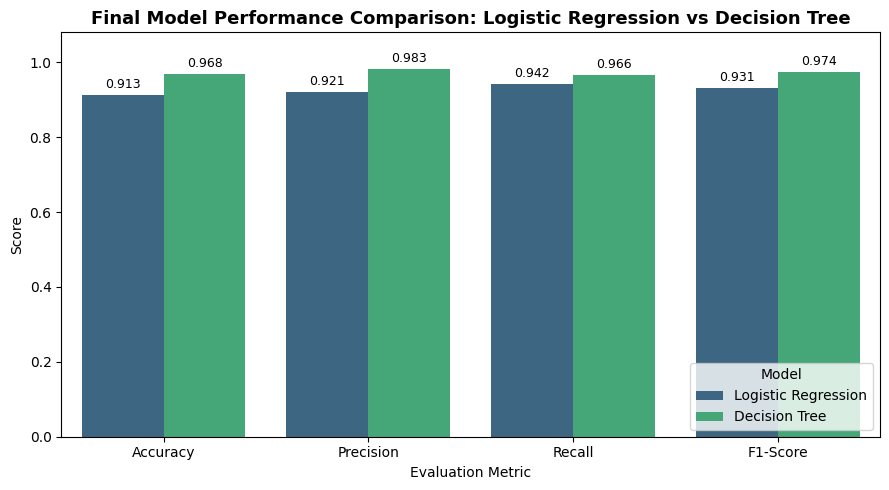

In [65]:
# STEP 19: FINAL COMPARISON & RESULTS

# 1. Compile Classification Model Results
results_summary = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_tree_test, y_tree_pred),
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_tree_test, y_tree_pred),
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_tree_test, y_tree_pred),
    ],
    "F1-Score": [
        f1_score(y_test, y_pred),
        f1_score(y_tree_test, y_tree_pred),
    ],
})

print("=" * 60)
print("FINAL CLASSIFICATION MODEL COMPARISON")
print("=" * 60)
print(results_summary.to_string(index=False))

# Identify the best classification model automatically
best_model_row = results_summary.loc[results_summary["Accuracy"].idxmax()]
print(
    f"\nBest Performing Model: {best_model_row['Model']} (Accuracy:"
    f" {best_model_row['Accuracy']*100:.2f}%)"
)

# 2. Compile Unsupervised Clustering Results
print("\n" + "=" * 60)
print("UNSUPERVISED CLUSTERING SUMMARY")
print("=" * 60)
print(f"K-Means Silhouette Score:               {sil_score:.4f}")
print(f"Hierarchical Clustering Silhouette:     {hier_sil_score:.4f}")

# 3. Visual Side-by-Side Comparison of Classification Metrics
results_melted = results_summary.melt(
    id_vars="Model", var_name="Metric", value_name="Score"
)

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=results_melted, x="Metric", y="Score", hue="Model", palette="viridis"
)
plt.title(
    "Final Model Performance Comparison: Logistic Regression vs Decision Tree",
    fontsize=13,
    fontweight="bold",
)
plt.ylim(0, 1.08)
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.legend(title="Model", loc="lower right")

# Add score labels on top of each bar
for container in ax.containers:
  ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

plt.tight_layout()
plt.show()